# Cancer Tumor Classification
Goal: 

In [19]:
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [8]:
# Initiate logging for tracking execution steps
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')

## 1. Data Ingestion
Load data from scikit-learn's Wisconsin Breast Cancer dataset

In [9]:
# Load data from scikit-learn
cancer_data = load_breast_cancer()
# print(cancer_data.keys())

# Extract feature arrays, numerical targets, and column names from Bunch
X_raw = cancer_data.data
y_raw = cancer_data.target
feature_names = cancer_data.feature_names

df = pd.DataFrame(X_raw, columns=feature_names)
df['Label'] = y_raw

# Map numeric label to its descriptive text labels
df['Diagnosis'] = pd.Series(y_raw).map({0: 'Malignant', 1:'Benign'})

logging.info(f"Data sucessfully ingested. Dimensions: {df.shape}")


INFO: Data sucessfully ingested. Dimensions: (569, 32)


## 2. Exploratory Data Analysis (EDA)

### 2.1 Visual Inspection

In [10]:
# Visual Inspection
dimensions = df.shape
print(f"Dataset Dimensionality: {dimensions[0]} patient samples, {dimensions[1]} columns")
display(df.head())

Dataset Dimensionality: 569 patient samples, 32 columns


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Label,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


The dataset consists of 32 columns and 569 patient samples. Of the 32 columns, 30 are numeric features representing cellular characteristics, and the remaining 2 columns represent the classification of the tumors numerically and categorically. The dataset has a large number of columns, which can introduce noise and cause visual complexity. This can be addressed using Principal Component Analysis (PCA), a compression tool that can condense the complex dimensions into a clean 2D scatter plot.

### 2.2 Missing Data Analysis

In [11]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nThere are {df.isnull().sum().sum()} missing values in the dataset")

Missing values per column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Label                      0
Diagnosis                  0
dtype: int64

There are 0 missing values in t

### 2.3 Class Distribution Analysis

In [12]:
# Check class distribution
class_counts = df['Diagnosis'].value_counts()
class_percentages = df['Diagnosis'].value_counts(normalize=True)*100

print("Class Distribution:")
for i, label in enumerate(class_counts.index): 
    count = class_counts.values[i]
    percentage = class_percentages.values[i]
    print(f"{label}: {count} samples ({percentage:.2f}%)")

Class Distribution:
Benign: 357 samples (62.74%)
Malignant: 212 samples (37.26%)


The dataset is moderately imbalanced (62.74% Benign vs. 37.26% Malignant). 
To handle this, we will implement stratification during our train-test split 
(`stratify=y`). This locks the identical 63/37 category ratio into both our 
training and validation sets, ensuring our model trains on a representative 
sample and that our final evaluation scores remain completely unbiased.


### 2.4 Scale Profiling

In [13]:
numeric_features = df.drop(columns=['Label', 'Diagnosis'])
display(numeric_features.describe().T[['mean', 'std', 'min', 'max']])


,mean,std,min,max
mean radius,14.127292,3.524049,6.981000,28.11000
mean texture,19.289649,4.301036,9.710000,39.28000
mean perimeter,91.969033,24.298981,43.790000,188.50000
mean area,654.889104,351.914129,143.500000,2501.00000
mean smoothness,0.096360,0.014064,0.052630,0.16340
mean compactness,0.104341,0.052813,0.019380,0.34540
mean concavity,0.088799,0.079720,0.000000,0.42680
mean concave points,0.048919,0.038803,0.000000,0.20120
mean symmetry,0.181162,0.027414,0.106000,0.30400
mean fractal dimension,0.062798,0.007060,0.049960,0.09744


From the scale profiling, we can see that some features, such as `mean smoothness`, have extremely small averages, while others, like `mean area`, have much larger averages. Furthermore, `mean area` has extreme right-skewness with a max of 2,501, which is about 1,847 greater than the average. This can cause mathematical risks when performing PCA, as PCA identifies maximum variance directions. The varied data will cause massive numbers to completely dominate the equations, causing PCA to treat these large values as the only important features. This will completely ignore other important features simply because their units are smaller. To prevent this distortion, a data standardization step like `StandardScaler` is needed to shift the features onto a uniform Gaussian scale before computing our PCA projections or training our model.

## 3. Data Standardization & Feature Engineering

### 3.1 Train-Test Split

In [14]:
# Split features columns from label columns
X = df.drop(columns=['Diagnosis', 'Label']).values
y = df['Label'].values

# Stratified train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=24, stratify=y)

# Split check
tot_rows = len(df)
train_ft_rows = len(X_train)
test_ft_rows = len(X_test)
train_per = train_ft_rows/tot_rows*100
test_per = test_ft_rows/tot_rows*100


print(f"Train Set: {train_ft_rows} feature rows; {len(y_train)} label rows")
print(f"Test Set: {test_ft_rows} feature rows; {(len(y_test))} label rows")
print(f"{train_per:.2f}% Train, {test_per:.2f}% Test")

Train Set: 455 feature rows; 455 label rows
Test Set: 114 feature rows; 114 label rows
79.96% Train, 20.04% Test


From the analysis, we can see that the train and test sets were split correctly according to an 80:20 split. According to the split, there will be information regarding 455 patients in the training set and 114 patients in the testing set. 

### 3.2 Feature Scaling
Now that we have split the data into train and test data, we can use `StandardScaler` from scikit-learn to standardize the data onto a uniform Gaussian distribution. This will prevent the prioritization of certain data over others. 

In [15]:
# initialize StandardScaler
scaler = StandardScaler()

# fit on training data
X_train_scaled = scaler.fit_transform(X_train)

# transform according to trained fitting
X_test_scaled = scaler.transform(X_test)  


When executing the code, `fit_tranform()` was exclusively used on the training set because `fit_transform()` stores the mean and standard deviation calculations in memory, which can then be re-applied for scaling transformation, using `.transform()`. This allows the **exact same** weights to be applied to the test set, which will prevent the scaler from learning any new information. This translates in real-life deployment, where our pipeline cannot account for or recalculate future data. 


## 4. Dimensionality Reduction (PCA)
Now that we have scaled our data, we can proceed with reducing the dimensionality of the data. As we mentioned before, PCA will reduce dimensionality, allowing us to view and understand the data in a simple, compressed 2D graph.

### 4.1 PCA Fitting & Variance Extraction

In [16]:
# initialize PCA to extract the top 2D of highest variance for coordinates
pca = PCA(n_components=2)

# fit on standardized training data
X_train_pca = pca.fit_transform(X_train_scaled)

# transform test data using trained fitting
X_test_pca = pca.transform(X_test_scaled)

# extract variance data to see how much data was retained
explained_var = pca.explained_variance_ratio_
total_var = explained_var.sum()*100
pc1_explained = explained_var[0]*100
pc2_explained = explained_var[1]*100


# Display variance data
print(f"PCA Variance Summary:")
print(f"Principle Component 1 (PC1): {pc1_explained:.2f}% variance")
print(f"Principle Component 2 (PC2): {pc2_explained:.2f}% variance")
print(f"Total Information retained: {total_var:.2f}%")




PCA Variance Summary:
Principle Component 1 (PC1): 44.00% variance
Principle Component 2 (PC2): 18.65% variance
Total Information retained: 62.64%


In data science, variance is information, therefore, the fact that we kept nearly two-thirds of our 30 features using just 2 variables is significant. This proves that our original datasetcontained highly correlated features, and PCA successfully stripped away the redundant noise while preserving the core biological signals needed for classification.

### 4.2 Visualization

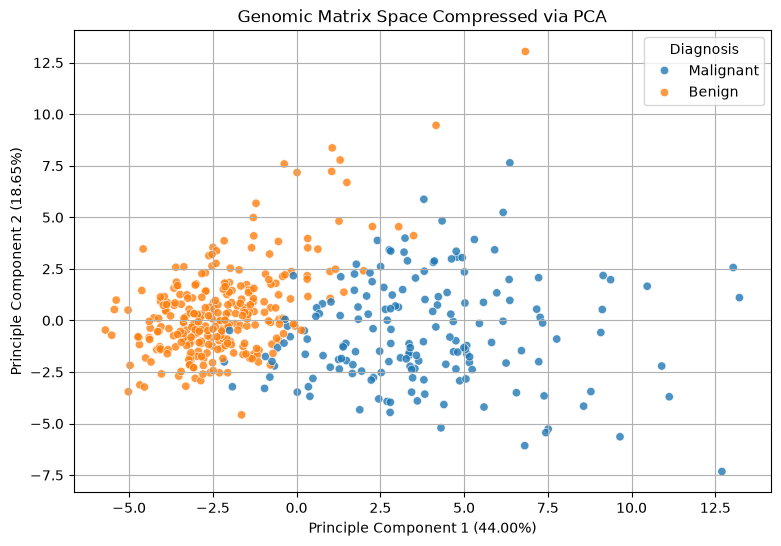

In [17]:
# create df with trained coordinates
# seaborn works best with structured pd df than numpy array
pca_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
pca_df['Diagnosis'] = pd.Series(y_train).map({0:'Malignant', 1:'Benign'})  # map temp column for graph legend 

# plot compressed graph
plt.figure(figsize=(9,6))  # create graph container
sb.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Diagnosis', alpha=0.8)  # generate and map points on graph

# add annotations to graph
plt.title("Genomic Matrix Space Compressed via PCA")
plt.xlabel(f"Principle Component 1 ({pc1_explained:.2f}%)")
plt.ylabel(f"Principle Component 2 ({pc2_explained:.2f}%)")
plt.grid(True)
plt.show()

The 2D compressed map displays a stark, clear visual layout, with the blue representing a benign diagnosis and red representing a malignant diagnosis. The benign cluster forms a dense, tightly packed population localized to the left of the graph, while the malignant cluster is more widely dispersed along the right side of the grid. This provides a clear physical separation between the two populations, validating our pipeline. Because the tumor groups do not overlap much, we can confirm that our preprocessing step has successfully exposed the underlying biology. With a distinct spatial boundary existing between the classes, we can use a Support Vector Machine (SVM) to calculate and draw a high-accuracy linear decision boundary to separate these tumors.


## 5. Model Training & Evaluation 



SVMs utilize specialized mathematical engines called _kernels_ to construct their decision boundaries:
* Linear (`kernel='linear'`): Constructs a flat, straight boundary with the lowest risk of overfitting.
* Radial Basis Function (`kernel='rbf'`): Constructs complex, hyper-flexible curves or circular bubbles. Ideal for chaotic, overlapping clusters, but carries a high risk of overfitting.
* Polynomial (`kernel='poly'`): Constructs arched, wavy boundaries optimized for data with gradual curvilinear trends or exponential feature interactions.
* Sigmoid (`kernel='sigmoid'`): Constructs S-curve layouts, primarily for simulating neural network activation behaviors. 

For this pipeline, we implement a _Linear SVM_ as the data exhibits a clear, diagonal spatial division between tumor classes. Furthermore, as the data do not heavily overlap, there is no reason for the more flexible kernels to memorize noisy border points or overfit our small clinical dataset.


In [ ]:
# initialize 
svm = SVC(kernel='linear', C=1.0, random_state=42)

# train using compressed data
svm.fit(X_train_pca, y_train)

# predict classification
y_pred = svm.predict(X_test_pca)

# check model accuracy
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=['Malignant', 'Benign'])
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn/(tn+fp)

print("Evaluation:")
print(f"Validation Model Accuracy: {accuracy*100:.2f}")
print(f"Specificity {specificity*100:.2f}%")
print(report)


Evaluation:
Validation Model Accuracy: 95.61
Specificity 92.86
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Based on our evaluation metrics, the model has about a 95.61% validation accuracy on completely unseen testing data. Furthermore, to evaluate the clinical safety of this model, we need to analyze the metrics through a medical oncology lens. In a medical situation, although accuracy is extremely important, in a situation with false diagnosis, it is much more detrimental to have false negatives as opposed to false positives. Therefore, we must particularly pay attention to Precision, Recall (Sensitivity), and Specificity (Selectivity). Our model achieves a Malignant Precision of 0.05, meaning that the pipeline accurately flags aggressive tumor cells 95% of the time, keeping the False Positive rate low at 5%. The model also achieves a Malignant Recall of 0.93, proving that it successfully catches 93% of aggressive cancer cases, leaving a minimal 7% False Negative rate. The clinical safety of this model is further validated by a high Specificity rate of 92.86%, demonstrating that our pipeline is highly adept at identifying benign tissue correctly, preventing unneeded medical panic or invasive follow-up. Hitting these marks using just two compressed spatial variables proves that our end-to-end architecture is highly stable, generalized, and viable for automated screening diagnostics.
